# 01 · Diagnóstico de los anuncios de Finca Raíz

**Objetivo:** conocer los datos *antes* de limpiarlos. Aquí NO modificamos nada; solo miramos.
Las reglas de limpieza las decidimos con lo que encontremos aquí.

**¿Qué es un notebook?** Un documento con celdas: unas de texto (como esta) y otras de código.
Cada celda de código se ejecuta con **Shift + Enter** y muestra su resultado justo debajo.
Ejecuta las celdas **en orden, de arriba hacia abajo**: cada una usa lo que crearon las anteriores.

## 1. Librerías y rutas

- **pandas** (`pd`): tablas de datos. Su objeto central es el `DataFrame`.
- **numpy** (`np`): cálculo numérico (logaritmos, arreglos).
- **matplotlib** (`plt`): la librería base de gráficas en Python.
- **seaborn** (`sns`): construida sobre matplotlib, hace gráficas estadísticas con menos código.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Mostrar más columnas y números sin notación científica (1.5e+06 -> 1,500,000)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

# Buscar la raíz del proyecto: subimos carpetas hasta encontrar requirements.txt
RAIZ = Path.cwd()
while not (RAIZ / "requirements.txt").exists():
    RAIZ = RAIZ.parent
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\KATANA\Documents\Universidad USB\Semestre 8\Deep Learning\Taller - Financiera\Vs Code\vivienda-estudiantil\vivienda-estudiantil


## 2. Cargar los datos

Tomamos el CSV más reciente que generó el parser en `data/interim/`.
`dtype={"id": str}` le dice a pandas que el id es texto (es un código, no un número para sumar).

In [2]:
archivo = sorted((RAIZ / "data" / "interim").glob("fincaraiz_*.csv"))[-1]
df = pd.read_csv(archivo, dtype={"id": str})
print(f"Archivo: {archivo.name}")
print(f"Filas (anuncios): {len(df):,}  |  Columnas: {df.shape[1]}")
df.head(3)

Archivo: fincaraiz_2026-10-23.csv
Filas (anuncios): 31,675  |  Columnas: 37


,id,fuente,url,titulo,tipo_inmueble,municipio,zona,barrio,direccion,lat,lon,precio,precio_con_admin,administracion,area_m2,habitaciones,banos,parqueaderos,piso,estrato,antiguedad_cod,antiguedad,estado,acepta_mascotas,contrato_minimo,amenidades,n_amenidades,descripcion,tipo_anunciante,inmobiliaria,img,n_imagenes,fecha_publicacion,fecha_actualizacion,fecha_scraping,municipio_busqueda,tipo_busqueda
0,192664455,fincaraiz,https://www.fincaraiz.com.co/apartaestudio-en-...,"Apartaestudio en Arriendo en Centro, Barbosa",Apartaestudio,Barbosa,NaN,Centro,KR 11 # 12 - 2,6.44,-75.33,"850,000.00","850,000.00",0.00,35.00,1.00,1.00,0.00,3.00,2.00,2.00,1 a 8 años,Usado,NaN,NaN,Barra estilo americano|Cocina Integral|Colegio...,8,Este apartaestudio en arriendo combina comodid...,inmobiliaria,ARRENDAMIENTOS BARBOSA,https://cdn2.infocasas.com.uy/repo/img/68e0574...,13.00,2025-07-21,2026-10-08,2026-10-23,barbosa,apartaestudios
1,194259729,fincaraiz,https://www.fincaraiz.com.co/apartaestudio-en-...,"Apartaestudio en Arriendo en Potrerito, Barbosa",Apartaestudio,Barbosa,NaN,Potrerito,"Boston, Comuna 10 - La Candelaria, Perímetro U...",6.43,-75.34,"670,000.00","670,000.00",0.00,25.00,1.00,1.00,1.00,1.00,2.00,2.00,1 a 8 años,Usado,NaN,NaN,Piso en Baldosa / Mármol|Sobre vía principal|...,4,APARTAESTUDIO RURAL EN ARRIENDO \n¿Buscas un l...,inmobiliaria,ARRENDAMIENTOS BARBOSA,https://cdn2.infocasas.com.uy/gen-ai/enhanced_...,12.00,2026-09-15,2026-09-15,2026-10-23,barbosa,apartaestudios
2,194426123,fincaraiz,https://www.fincaraiz.com.co/apartamento-en-ar...,"Apartamento en Arriendo en El porton, Barbosa",Apartamento,Barbosa,NaN,El porton,KR 13 # 11 - 34,6.44,-75.33,"1,400,000.00","1,400,000.00",0.00,120.00,4.00,2.00,0.00,0.00,2.00,3.00,9 a 15 años,Usado,NaN,NaN,Baño Auxiliar|Cocina Integral|Colegios / Unive...,10,Descubra este apartamento funcional en arriend...,inmobiliaria,ARRENDAMIENTOS BARBOSA,https://cdn2.infocasas.com.uy/repo/img/6ad68fe...,11.00,2026-10-19,2026-10-19,2026-10-23,barbosa,apartamentos


## 3. Tipos de dato y vacíos

`df.info()` muestra, por columna, cuántos valores **no vacíos** hay y de qué tipo son
(`float64` = número decimal, `int64` = entero, `str`/`object` = texto).
Si una columna que debería ser número aparece como texto, hay un problema de formato.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31675 entries, 0 to 31674
Data columns (total 37 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   31675 non-null  str    
 1   fuente               31675 non-null  str    
 2   url                  31675 non-null  str    
 3   titulo               31675 non-null  str    
 4   tipo_inmueble        31675 non-null  str    
 5   municipio            31675 non-null  str    
 6   zona                 17700 non-null  str    
 7   barrio               31460 non-null  str    
 8   direccion            31675 non-null  str    
 9   lat                  31675 non-null  float64
 10  lon                  31675 non-null  float64
 11  precio               31675 non-null  float64
 12  precio_con_admin     31675 non-null  float64
 13  administracion       31675 non-null  float64
 14  area_m2              30850 non-null  float64
 15  habitaciones         31675 non-null  float64
 1

## 4. Resumen estadístico de las variables numéricas

`describe()` calcula, para cada columna: cantidad, media, desviación estándar, mínimo, percentiles y máximo.

**Cómo leerlo:** fíjate sobre todo en el **mínimo**, el **máximo** y los percentiles **1 %** y **99 %**.
Si el máximo está muy lejos del 99 %, hay valores extremos (posibles errores de digitación).

In [4]:
numericas = ["precio", "administracion", "area_m2", "habitaciones", "banos",
             "parqueaderos", "piso", "estrato", "n_amenidades"]
df[numericas].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
precio,"31,675.00","9,171,882.88","484,359,113.96",0.00,"1,250,000.00","1,800,000.00","3,100,000.00","4,300,000.00","6,500,000.00","15,000,000.00","26,500,000.00","85,000,000,000.00"
administracion,"31,675.00","19,539.17","202,223.32",0.00,0.00,0.00,0.00,0.00,0.00,0.00,"760,260.00","15,000,000.00"
area_m2,"30,850.00",337.62,"23,952.76",0.00,22.00,44.00,68.00,88.00,136.00,336.00,"1,025.10","3,700,000.00"
habitaciones,"31,675.00",2.68,1.23,-1.00,0.00,1.00,2.00,3.00,3.00,4.00,6.00,39.00
banos,"31,675.00",2.51,1.15,0.00,1.00,1.00,2.00,2.00,3.00,5.00,6.00,28.00
parqueaderos,"31,675.00",1.29,1.34,-5.00,0.00,0.00,1.00,1.00,2.00,3.00,6.00,127.00
piso,"31,213.00",3.29,7.96,-1.00,0.00,0.00,0.00,0.00,4.00,18.00,18.00,802.00
estrato,"31,675.00",5.41,7.94,0.00,2.00,3.00,4.00,5.00,6.00,6.00,6.00,110.00
n_amenidades,"31,675.00",19.68,11.82,0.00,0.00,1.00,10.00,20.00,27.00,40.00,52.00,66.00


## 5. "Ceros disfrazados"

En los portales, un **0** muchas veces significa *"el anunciante no lo dijo"*, no un cero real.
Por ejemplo: un apartamento en el **piso 0** o con **administración $0** casi nunca es real.
Contamos cuántos ceros hay en cada columna para decidir dónde un 0 debe tratarse como dato faltante.

In [5]:
ceros = pd.DataFrame({
    "ceros": (df[numericas] == 0).sum(),
    "% ceros": ((df[numericas] == 0).mean() * 100).round(1),
    "% vacíos": (df[numericas].isna().mean() * 100).round(1),
})
ceros

,ceros,% ceros,% vacíos
precio,1,0.00,0.00
administracion,31046,98.00,0.00
area_m2,6,0.00,2.60
habitaciones,328,1.00,0.00
banos,189,0.60,0.00
parqueaderos,6190,19.50,0.00
piso,18083,57.10,1.50
estrato,111,0.40,0.00
n_amenidades,1503,4.70,0.00


## 6. Valores categóricos: municipio, tipo de inmueble, estrato

`value_counts()` cuenta cuántas veces aparece cada valor. Sirve para detectar
nombres escritos de varias formas y valores imposibles (como un estrato 110).

In [6]:
print("MUNICIPIO\n", df["municipio"].value_counts().to_string(), "\n")
print("TIPO DE INMUEBLE\n", df["tipo_inmueble"].value_counts().to_string(), "\n")
print("ESTRATO\n", df["estrato"].value_counts().sort_index().to_string(), "\n")
print("TIPO DE ANUNCIANTE\n", df["tipo_anunciante"].value_counts(dropna=False).to_string())

MUNICIPIO
 municipio
Medellín              18988
Envigado               7013
Sabaneta               3289
Bello                   822
Itaguí                  730
La estrella             707
Copacabana               49
Caldas                   23
El Retiro                14
Rionegro                 10
Girardota                 8
Barbosa                   6
San jose                  3
Linares                   2
La calera                 2
San Vicente Ferrer        1
El dorado                 1
La ceja                   1
Alejandria                1
El encanto                1
El castillo               1
La palma                  1
La Unión                  1
Andalucia                 1 

TIPO DE INMUEBLE
 tipo_inmueble
Apartamento      25596
Casa              4152
Apartaestudio     1889
Habitación          38 

ESTRATO
 estrato
0.00        111
1.00         34
2.00        369
3.00       3384
4.00       7927
5.00       9230
6.00      10436
7.00          1
40.00         1
55.00         1
60

## 7. Primera gráfica: distribución del precio

Los precios de arriendo tienen una **cola larga**: muchos entre 1 y 3 millones y unos pocos de 20+ millones.
En escala normal, la cola aplasta la gráfica. Por eso usamos **escala logarítmica** en el eje X:
cada marca multiplica por 10 en vez de sumar, y así se ve bien toda la distribución.

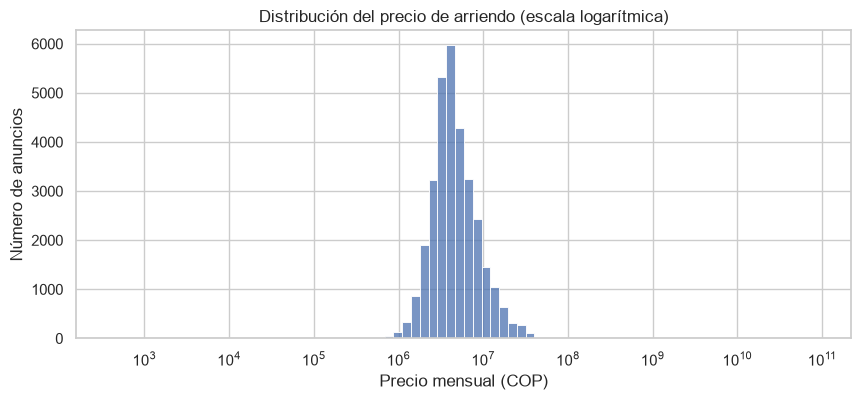

Precio mediano: $ 4,300,000
Anuncios con precio < $300.000: 6
Anuncios con precio > $30.000.000: 186


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df["precio"], bins=80, log_scale=True, ax=ax)
ax.set_title("Distribución del precio de arriendo (escala logarítmica)")
ax.set_xlabel("Precio mensual (COP)")
ax.set_ylabel("Número de anuncios")
plt.show()

print("Precio mediano: $", f"{df['precio'].median():,.0f}")
print("Anuncios con precio < $300.000:", (df["precio"] < 300_000).sum())
print("Anuncios con precio > $30.000.000:", (df["precio"] > 30_000_000).sum())

## 8. Precios fuera de lo normal: un vistazo

Vemos los 5 más baratos y los 5 más caros para entender qué tipo de errores hay.

In [8]:
cols = ["tipo_inmueble", "municipio", "barrio", "precio", "area_m2", "habitaciones", "estrato", "url"]
print("MÁS BARATOS")
display(df.nsmallest(5, "precio")[cols])
print("MÁS CAROS")
display(df.nlargest(5, "precio")[cols])

MÁS BARATOS


,tipo_inmueble,municipio,barrio,precio,area_m2,habitaciones,estrato,url
8270,Casa,Envigado,Envigado,0.00,89.00,3.00,4.00,https://www.fincaraiz.com.co/casa-en-arriendo-...
11347,Apartamento,Medellín,Loma de los Gonzalez,410.00,64.00,1.00,6.00,https://www.fincaraiz.com.co/apartamento-en-ar...
11348,Apartamento,Medellín,San miguel,"1,700.00",54.00,2.00,4.00,https://www.fincaraiz.com.co/apartamento-en-ar...
9275,Apartamento,La estrella,La Aldea,"30,000.00",1.00,0.00,4.00,https://www.fincaraiz.com.co/apartamento-en-ar...
9167,Apartamento,Itaguí,San pio x,"180,000.00",84.00,3.00,3.00,https://www.fincaraiz.com.co/apartamento-en-ar...


MÁS CAROS


,tipo_inmueble,municipio,barrio,precio,area_m2,habitaciones,estrato,url
27597,Casa,Medellín,Prado,"85,000,000,000.00","2,450.00",4.00,4.00,https://www.fincaraiz.com.co/casa-en-arriendo-...
8284,Casa,Girardota,Portachuelo,"14,000,000,000.00",496.00,6.00,4.00,https://www.fincaraiz.com.co/casa-en-arriendo-...
8086,Casa,Envigado,Loma de las brujas,"2,000,000,000.00",258.00,5.00,5.00,https://www.fincaraiz.com.co/casa-en-arriendo-...
18229,Apartamento,Medellín,San Lucas,"1,670,000,000.00",157.00,2.00,6.00,https://www.fincaraiz.com.co/apartamento-en-ar...
18230,Apartamento,Medellín,Los Balsos,"1,050,000,000.00",137.00,3.00,6.00,https://www.fincaraiz.com.co/apartamento-en-ar...
